# A — Préparer les données
Base préparée à partir des captures, à comparer au Sprint 1 du groupe.
Indices : ^GSPC (S&P 500), ^GSPTSE (TSX), ^VIX. Début : 2000-01-01. Dernier jour demandé : 2026-10-12, dernière séance complète au moment de la préparation. Ne pas demander des dates futures.
Rendement simple en %. `rv` désigne ici la **variance journalière Garman–Klass en %2**. Confirmer cette convention avec le groupe : certains scripts attendent une volatilité ou une variance en %².
Garman–Klass utilise les QUATRE prix OHLC : 0,5 ln(H/L)² − (2 ln(2)−1) ln(C/O)². La volatilité journalière est la racine de cette variance. Ce proxy n'est pas une variance réalisée intrajournalière et ne capture pas directement les sauts entre séances.


In [1]:
from pathlib import Path
import json, hashlib, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
assert (ROOT / 'notebooks').is_dir(), 'Ouvrir depuis la racine du dépôt ou notebooks/'
for folder in ['data/raw', 'figures', 'results']: (ROOT / folder).mkdir(parents=True, exist_ok=True)
START = '2000-01-01'
END = '2026-10-13'  # borne exclusive : inclut le 12 octobre


In [2]:
def get_raw(symbol, name):
    path = ROOT / 'data/raw' / f'{name}.csv'
    if path.exists():
        frame = pd.read_csv(path, index_col=0, parse_dates=True)
        print('Copie brute réutilisée :', name)
    else:
        frame = yf.download(symbol, start=START, end=END, auto_adjust=False,
                            multi_level_index=False, progress=False)
        if frame is None or frame.empty:
            raise RuntimeError(f'Aucune donnée pour {symbol}. Vérifier connexion et source.')
        if isinstance(frame.columns, pd.MultiIndex):
            frame.columns = frame.columns.get_level_values(0)
        frame.index.name = 'Date'
        frame.to_csv(path)  # conserver avant nettoyage
        meta = {'ticker': symbol, 'start': START, 'end_exclusive': END,
                'downloaded_utc': pd.Timestamp.now(tz='UTC').isoformat(),
                'yfinance_version': importlib.metadata.version('yfinance'),
                'sha256': hashlib.sha256(path.read_bytes()).hexdigest()}
        path.with_suffix('.json').write_text(json.dumps(meta, indent=2))
    frame.index = pd.to_datetime(frame.index).tz_localize(None).normalize()
    frame.columns = frame.columns.str.lower().str.replace(' ', '_')
    assert not frame.index.duplicated().any(), 'Dates dupliquées à examiner'
    return frame.sort_index()
raw = {name: get_raw(symbol, name) for name, symbol in
       [('spx', '^GSPC'), ('tsx', '^GSPTSE'), ('vix', '^VIX')]}


Copie brute réutilisée : spx
Copie brute réutilisée : tsx
Copie brute réutilisée : vix


In [3]:
def prepare(frame, vix):
    prices = frame[['open', 'high', 'low', 'close']].apply(pd.to_numeric, errors='coerce')
    valid = (np.isfinite(prices).all(axis=1) & (prices > 0).all(axis=1)
             & (prices.high >= prices[['open','close','low']].max(axis=1))
             & (prices.low <= prices[['open','close','high']].min(axis=1)))
    # Ne pas supprimer les dates avant le rendement : évite de créer un rendement sur plusieurs séances.
    prices = prices.where(valid)
    ret = 100 * np.log(prices.close).diff()
    rv = .5 * np.log(prices.high / prices.low)**2 - (2*np.log(2)-1)*np.log(prices.close / prices.open)**2
    assert not (rv.dropna() < -1e-12).any(), 'Variance négative : contrôler les prix'
    rv = rv.clip(lower=0)
    out = prices.assign(ret=ret, rv=10000 * rv)
    # Alignement exact : aucune valeur future ni interpolation. Le TSX a des jours fériés différents.
    dates = vix.index.union(out.index).sort_values()
    vix_complete = vix['close'].reindex(dates).ffill(limit=3)
    out['vix'] = vix_complete.reindex(out.index)
    keep = np.isfinite(out).all(axis=1) & (out.vix > 0) & (out.high > out.low)
    excluded = out.loc[~keep].copy()
    return out.loc[keep].rename_axis('Date'), excluded
prepared = {}
for name in ['spx', 'tsx']:
    df, excluded = prepare(raw[name], raw['vix'])
    assert df.index.is_monotonic_increasing and df.index.is_unique
    assert df.columns.tolist() == ['open','high','low','close','ret','rv','vix']
    assert not df.empty and (df.rv > 0).all()
    df.to_csv(ROOT / 'data' / f'{name}.csv')
    excluded.to_csv(ROOT / 'results' / f'{name}_dates_exclues.csv')
    prepared[name] = df
    print(name, len(df), 'lignes ;', df.index.min(), 'à', df.index.max(), '; exclues :', len(excluded))
    if len(df) < 6000: print('ALERTE : couverture historique à contrôler ; ne pas inventer de lignes.')
    display(df.head())


spx 6733 lignes ; 2000-01-04 00:00:00 à 2026-10-12 00:00:00 ; exclues : 1


,open,high,low,close,ret,rv,vix
Date,,,,,,,
2000-01-04,1455.219971,1455.219971,1397.430054,1399.420044,-3.909918,2.304785,27.010000
2000-01-05,1399.420044,1413.270020,1377.680054,1402.109985,0.192034,3.238335,26.410000
2000-01-06,1402.109985,1411.900024,1392.099976,1403.449951,0.095522,0.993764,25.730000
2000-01-07,1403.449951,1441.469971,1400.729980,1441.469971,2.672995,1.349778,21.719999
2000-01-10,1441.469971,1464.359985,1441.469971,1457.599976,1.112782,0.762737,21.709999


tsx 6713 lignes ; 2000-01-05 00:00:00 à 2026-10-09 00:00:00 ; exclues : 12


,open,high,low,close,ret,rv,vix
Date,,,,,,,
2000-01-05,8100.200195,8147.200195,8018.600098,8119.399902,-1.019488,1.244065,26.410000
2000-01-06,8137.000000,8186.399902,8075.700195,8114.200195,-0.064061,0.896380,25.730000
2000-01-07,8193.400391,8430.000000,8193.400391,8429.400391,3.811000,0.937111,21.719999
2000-01-10,8544.299805,8610.799805,8509.099609,8602.500000,2.032722,0.527781,21.709999
2000-01-11,8581.599609,8634.700195,8442.599609,8442.599609,-1.876259,1.500828,22.500000


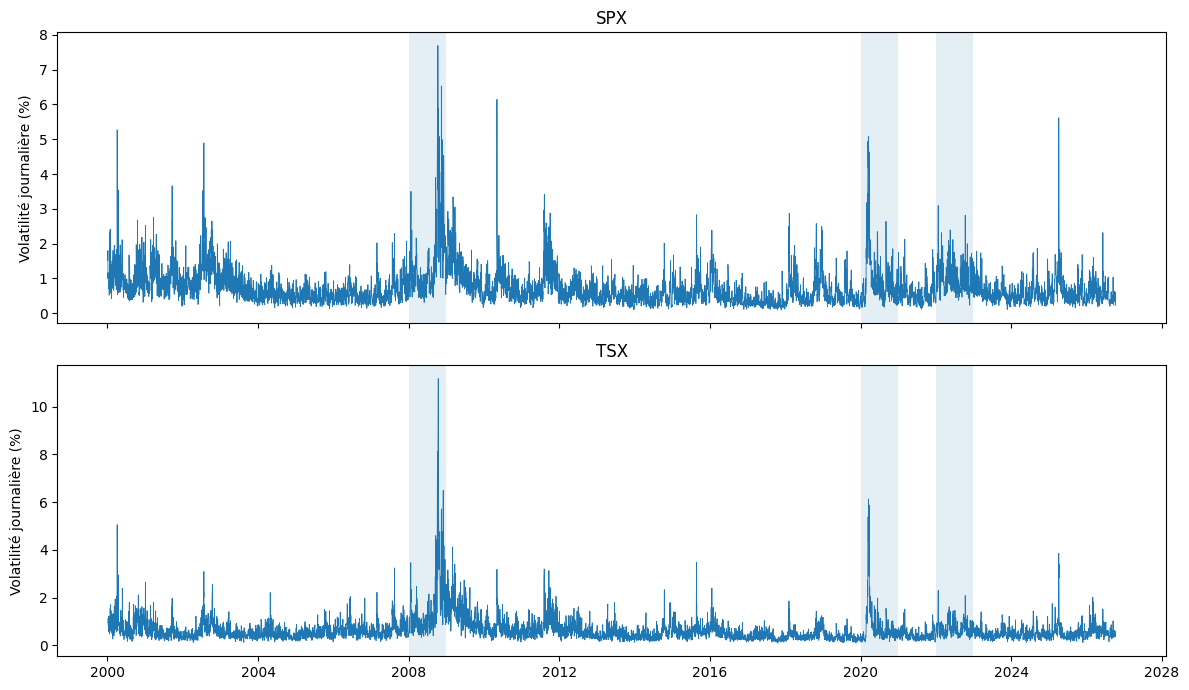

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for ax, (name, df) in zip(axes, prepared.items()):
    ax.plot(df.index, np.sqrt(df.rv), linewidth=.6)
    ax.set(title=name.upper(), ylabel='Volatilité journalière (%)')
    for year in [2008, 2020, 2022]:
        ax.axvspan(pd.Timestamp(f'{year}-01-01'), pd.Timestamp(f'{year}-12-31'), alpha=.12)
fig.tight_layout()
fig.savefig(ROOT / 'figures/volatilite_gk.png', dpi=160)
plt.show()


In [5]:
spx = prepared['spx']
tsx = prepared['tsx']
print("Date du maximum de variance SPX :", spx['rv'].idxmax())
proportion = (tsx['open'] == tsx['close'].shift(1)).mean()
print("Test TSX :", round(100 * proportion, 2), "%")


Date du maximum de variance SPX : 2008-10-10 00:00:00
Test TSX : 3.31 %


## Observations à rédiger après exécution
- Période effective et nombre de lignes de chaque indice : …
- Dates exclues et raison (prix absents, VIX absent, première observation) : …
- Pics observés en 2008, 2020 et 2022 : décrire les résultats, sans forcer le graphique.
- Comparaison S&P 500 / TSX : …
- Faire également les vérifications exactes du Sprint 1, non fourni.
**Prévision ultérieure** : construire les variables à t pour une cible à t+1 ; découpage chronologique, aucun mélange aléatoire des dates. Ne jamais utiliser le VIX de t+1 comme prédicteur de t+1.
